# Smart Outcome Predictor
Ensemble-based system for an EdTech platform: 

**(1) Classification** - will a student complete the course? 

**(2) Regression** - what will the final score be?

## Part A - Conceptual Foundation

### 1. Ensemble Learning

- **Definition:** Ensemble learning is a machine learning technique that combines multiple models to produce more accurate and reliable predictions than a single model.
- It works on the principle that different models can make different errors, and combining their predictions can improve overall performance.
- The main objective is to improve accuracy, reduce variance, and sometimes reduce bias.
- Ensemble learning includes techniques such as **Bagging, Boosting, Voting, and Stacking**.
- For example, combining Decision Tree, Logistic Regression, and Random Forest predictions can improve loan default classification.
- **Key Point:** Ensemble learning creates a stronger predictor by combining multiple models.

### 2. Bagging vs. Boosting vs. Voting

#### A. Bagging (Bootstrap Aggregating)

- Bagging trains multiple models independently on different bootstrap samples of the training dataset.
- Bootstrap samples are created by randomly selecting observations **with replacement**.
- The models can be trained in parallel because they do not depend on one another.
- Their predictions are combined using majority voting for classification or averaging for regression.
- Bagging primarily reduces variance and helps control overfitting.
- **Example:** Random Forest.

#### B. Boosting

- Boosting trains multiple weak learners sequentially, where each new learner focuses on improving the existing ensemble.
- Depending on the algorithm, it focuses on misclassified observations or the remaining errors in the predictions.
- Each learner contributes to the final prediction, often through a weighted combination.
- Boosting can reduce bias and improve predictive accuracy, but poorly tuned models may overfit.
- Unlike bagging, boosting generally depends on the results of previous learners.
- **Examples:** AdaBoost, Gradient Boosting, and XGBoost.

#### C. Voting

- Voting combines predictions from multiple machine learning models using a predefined aggregation rule.
- **Hard Voting:** Selects the class predicted by the majority of models.
- **Soft Voting:** Averages the predicted class probabilities and selects the class with the highest average probability.
- Models can be trained independently, and their predictions are combined during inference.
- Voting can improve prediction performance when the models provide complementary information.
- **Example:** Combining Logistic Regression, SVM, and Decision Tree predictions.

### 3. Bias-Variance Trade-off

- **Bias** refers to errors caused by overly simplistic assumptions in a machine learning model. High bias leads to underfitting.
- **Variance** refers to how sensitive a model is to changes in the training data. High variance can lead to overfitting.
- **Underfitting** occurs when a model fails to learn important patterns, while **overfitting** occurs when it learns the training data too closely.
- Bagging primarily reduces variance by combining predictions from multiple models trained on different samples.
- Boosting can reduce bias by sequentially improving the predictions of weak learners, although it may also affect variance.
- The objective is to balance bias and variance to achieve good generalization on unseen data.

### 4. Voting vs. Stacking

#### A. Voting

- Voting combines predictions from multiple base models using a fixed rule.
- Hard voting selects the class receiving the majority of votes.
- Soft voting averages the predicted probabilities and selects the class with the highest average probability.
- It is simple to implement and does not require training an additional model to combine predictions.
- Its performance depends on the quality and diversity of the base models.

#### B. Stacking

- Stacking combines multiple base models using another model called a **meta-learner**.
- First, the base models generate predictions, which become input features for the meta-learner.
- The meta-learner learns how to combine the base models' predictions to improve the final output.
- Out-of-fold predictions are commonly used to train the meta-learner and reduce data leakage.
- Stacking can learn more complex combinations than voting, but it is more computationally expensive.

### 5. AdaBoost vs. XGBoost

#### A. AdaBoost (Adaptive Boosting)

- AdaBoost is a boosting algorithm that combines multiple weak learners to create a stronger model.
- It increases the weights of misclassified training examples so subsequent learners focus more on difficult cases.
- It commonly uses shallow Decision Trees, called **decision stumps**, as weak learners.
- Each learner contributes to the final prediction according to its assigned weight.
- AdaBoost is relatively simple but can be sensitive to noisy data and outliers.
- **Key Point:** AdaBoost focuses on correcting mistakes by adjusting the weights of training examples.

#### B. XGBoost (Extreme Gradient Boosting)

- XGBoost is an optimized implementation of gradient boosting designed for efficient and accurate model training.
- It builds trees sequentially to improve predictions by minimizing a specified loss function.
- It uses gradient-based optimization and regularization, including L1 and L2 penalties, to help control overfitting.
- It supports features such as shrinkage, row and column subsampling, and built-in handling of missing values.
- It is widely used for structured and tabular datasets, although performance depends on the data and parameter settings.
- **Key Point:** XGBoost combines gradient boosting with optimization and regularization techniques.

#### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import json
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (BaggingClassifier, BaggingRegressor, AdaBoostClassifier, AdaBoostRegressor,
                                VotingClassifier, StackingClassifier, StackingRegressor)
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                                mean_absolute_error, mean_squared_error, r2_score, confusion_matrix, ConfusionMatrixDisplay)

## Part B - Dataset Understanding & Preparation

In [2]:
df = pd.read_csv("../Dataset/Smart_Outcome_Predictor_Dataset.csv")
print(f"Shape : {df.shape}")
df.head()

Shape : (5200, 19)


,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             5200 non-null   int64  
 1   age                    5200 non-null   int64  
 2   country_region         5200 non-null   str    
 3   device_type            5200 non-null   str    
 4   education_background   5200 non-null   str    
 5   course_level           5200 non-null   str    
 6   course_category        5200 non-null   str    
 7   course_start_date      5200 non-null   str    
 8   week_of_year           5200 non-null   int64  
 9   sessions               5200 non-null   int64  
 10  time_spent_hours       5088 non-null   float64
 11  videos_watched         5200 non-null   int64  
 12  quiz_attempts          5200 non-null   int64  
 13  assignments_submitted  5200 non-null   int64  
 14  forum_posts            5200 non-null   int64  
 15  avg_quiz_score 

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
student_id,5200.0,702600.500000,1501.255031,700001.000,701300.75000,702600.500,703900.250,705200.0
age,5200.0,24.339615,5.578864,16.000,20.00000,24.000,28.000,45.0
week_of_year,5200.0,26.621538,15.007731,1.000,14.00000,27.000,40.000,52.0
sessions,5200.0,19.121923,10.726708,1.000,11.00000,17.000,25.000,94.0
time_spent_hours,5088.0,18.216156,10.734114,0.600,10.30000,16.100,23.800,76.8
videos_watched,5200.0,25.852885,17.720493,0.000,13.00000,23.000,35.000,158.0
quiz_attempts,5200.0,6.995769,2.568017,0.000,5.00000,7.000,9.000,20.0
assignments_submitted,5200.0,3.835769,1.951802,0.000,2.00000,4.000,5.000,12.0
forum_posts,5200.0,1.585577,1.270640,0.000,1.00000,1.000,2.000,8.0
avg_quiz_score,5119.0,66.842626,13.813992,0.000,57.50000,66.900,76.200,100.0


### B1. Features and targets

In [3]:
T_CLS = 'completion_status'
T_REG = 'final_score'
DROP = ['student_id', 'course_start_date']          
FEATURES = [c for c in df.columns if c not in DROP + [T_CLS, T_REG]]   
CAT = ['country_region', 'device_type', 'education_background', 'course_level', 'course_category']
NUM = [c for c in FEATURES if c not in CAT]
print('numeric    :', NUM)
print('categorical:', CAT)
print('Classification target:', T_CLS, '| Regression target:', T_REG)

numeric    : ['age', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate']
categorical: ['country_region', 'device_type', 'education_background', 'course_level', 'course_category']
Classification target: completion_status | Regression target: final_score


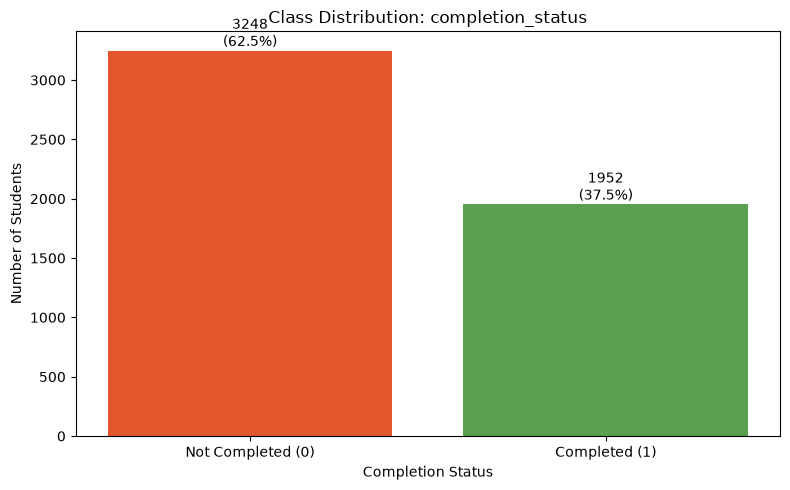

In [4]:
vc = df[T_CLS].value_counts().sort_index()
plt.figure(figsize=(8, 5))
bars = plt.bar(
    ['Not Completed (0)', 'Completed (1)'],
    [vc.get(0, 0), vc.get(1, 0)],
    color=['#E4572E', '#59A14F']
)

for i, v in enumerate([vc.get(0, 0), vc.get(1, 0)]):
    plt.text(i, v, f'{v}\n({v / len(df):.1%})', ha='center', va='bottom')

plt.title('Class Distribution: completion_status')
plt.ylabel('Number of Students')
plt.xlabel('Completion Status')
plt.tight_layout()
plt.savefig("../Images/01.class_disribution.png")
plt.show()

**Imterpretation :** 
- The bar chart shows the number and percentage of students who completed the course (1) and those who did not (0).
- It helps identify class imbalance, which can affect the performance of classification models.

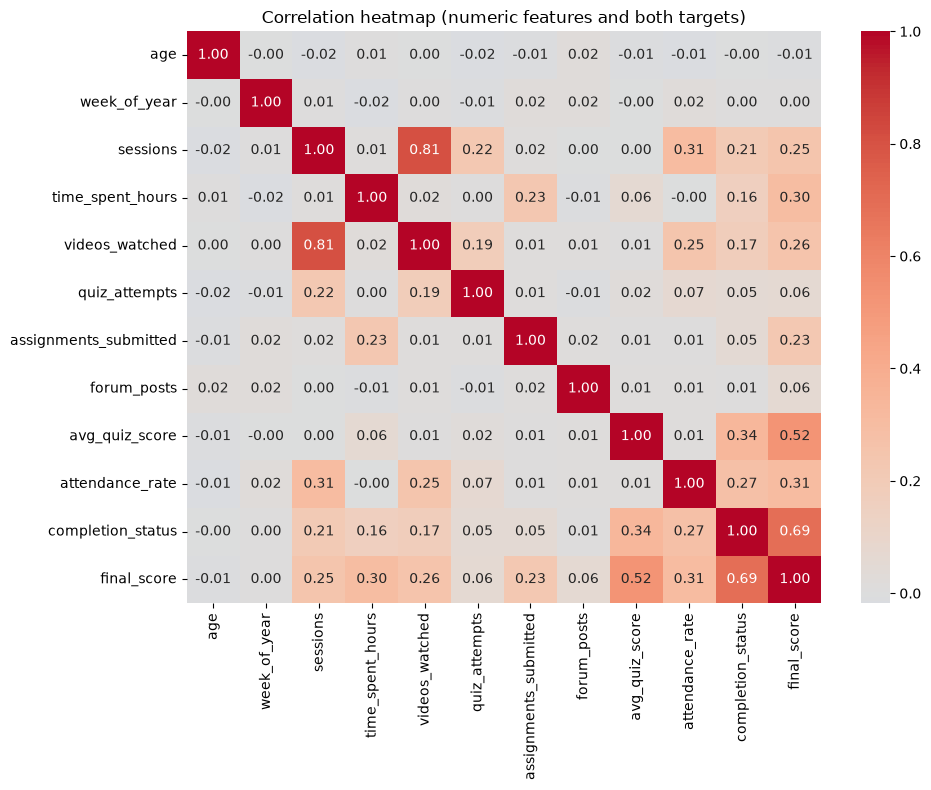

In [5]:
corr = df.select_dtypes('number').drop(columns='student_id').corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap (numeric features and both targets)')
plt.tight_layout()
plt.savefig('../Images/02_correlation_heatmap.png')
plt.show()

**Interpretation:** **avg_quiz_score** is the strongest predictor of both completion (+0.34) and final score (+0.52), followed by attendance, sessions, videos watched and time spent. **age**, **week_of_year** and **forum_posts** have almost no linear relationship. Correlations are moderate, so we expect only moderate accuracy (no perfect model).

### B2. Train-test split (same rows for both tasks)

In [6]:
X = df[FEATURES]
X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, df[T_CLS], df[T_REG], test_size=0.2, stratify=df[T_CLS], random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Completion rate  train: %.3f | test: %.3f' % (yc_train.mean(), yc_test.mean()))

Train: (4160, 15)  Test: (1040, 15)
Completion rate  train: 0.375 | test: 0.375


### B3. Preprocessing - scaling, KNN imputation (numeric) and constant-fill + one-hot encoding (categorical)

In [7]:
def make_preprocessor():
    num_pipe = Pipeline([
        ('scale', StandardScaler()), 
        ('knn', KNNImputer(n_neighbors=5))
    ])
    
    cat_pipe = Pipeline([
        ('fill', SimpleImputer(strategy='constant', fill_value='Unknown')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    
    return ColumnTransformer([('num', num_pipe, NUM), ('cat', cat_pipe, CAT)])

prep = make_preprocessor()
Xtr = prep.fit_transform(X_train)
Xte = prep.transform(X_test)
print('After preprocessing -> train', Xtr.shape, '| test', Xte.shape)

After preprocessing -> train (4160, 30) | test (1040, 30)


**Interpretation:** Preprocessing is wrapped in a **ColumnTransformer** (scale + KNN-impute numeric, one-hot categorical) giving 30 model features and zero NaNs. It is fitted on the training set only, so the test set has no leakage. student_id and course_start_date were dropped, and each target is excluded from the other task's features.

## Part C - Bagging (single base model vs Bagging)

In [8]:
cls_rows, reg_rows, cls_models, reg_models = [], [], {}, {}

def eval_cls(name, model):
    model.fit(Xtr, yc_train)
    pred = model.predict(Xte)
    p = model.predict_proba(Xte)[:, 1] if hasattr(model, 'predict_proba') else pred 
    
    cls_models[name] = model
    cls_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(yc_test, pred),
        'Precision': precision_score(yc_test, pred),
        'Recall': recall_score(yc_test, pred),
        'F1': f1_score(yc_test, pred),
        'AUC': roc_auc_score(yc_test, p),
        'Train_Acc': accuracy_score(yc_train, model.predict(Xtr))
    })

def eval_reg(name, model):
    model.fit(Xtr, yr_train)
    pred = model.predict(Xte)
    
    reg_models[name] = model
    reg_rows.append({
        'Model': name,
        'MAE': mean_absolute_error(yr_test, pred),
        'RMSE': np.sqrt(mean_squared_error(yr_test, pred)),
        'R2': r2_score(yr_test, pred),
        'Train_R2': r2_score(yr_train, model.predict(Xtr))
    })

In [10]:
eval_cls('Decision Tree', DecisionTreeClassifier(random_state=42))
eval_cls('Bagging Classifier', BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100, 
                                                oob_score=True, random_state=42, n_jobs=-1))

eval_reg('Decision Tree', DecisionTreeRegressor(random_state=42))
eval_reg('Bagging Regressor', BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=100, 
                                                oob_score=True, random_state=42, n_jobs=-1))

print('Bagging Classifier OOB accuracy:', round(cls_models['Bagging Classifier'].oob_score_, 4))
print('Bagging Regressor OOB R2:', round(reg_models['Bagging Regressor'].oob_score_, 4))

print("\nClassification")
display(pd.DataFrame(cls_rows).drop_duplicates(subset=['Model']).round(4))
print("\nRegressor")
display(pd.DataFrame(reg_rows).drop_duplicates(subset=['Model']).round(4))

Bagging Classifier OOB accuracy: 0.6988
Bagging Regressor OOB R2: 0.4513

Classification


,Model,Accuracy,Precision,Recall,F1,AUC,Train_Acc
0,Decision Tree,0.6173,0.4903,0.5205,0.5050,0.5979,1.0
1,Bagging Classifier,0.7058,0.6193,0.5590,0.5876,0.7584,1.0



Regressor


,Model,MAE,RMSE,R2,Train_R2
0,Decision Tree,11.1783,14.1096,-0.0936,1.0000
1,Bagging Regressor,8.3061,10.2951,0.4178,0.9246


**Interpretation:** A single unpruned Decision Tree memorises the training data (train accuracy 1.00) but generalises poorly (test accuracy 0.617, AUC 0.598; regression R2 -0.11). Bagging 100 trees reduces this variance sharply: accuracy 0.706, AUC 0.758, and regression RMSE 14.19 -> 10.30 (R2 0.417). OOB scores (0.699 accuracy, 0.451 R2) agree with test results, giving a free validation estimate.

## Part D - Boosting (AdaBoost & XGBoost)
### D1. AdaBoost

In [11]:
eval_cls('AdaBoost Classifier', AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200, 
                                                    learning_rate=0.5, random_state=42))

eval_reg('AdaBoost Regressor', AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4), n_estimators=100, 
                                                    learning_rate=0.5, random_state=42))

ada_c = cls_models['AdaBoost Classifier']
ada_r = reg_models['AdaBoost Regressor']
acc_stage = [accuracy_score(yc_test, p) for p in ada_c.staged_predict(Xte)]
r2_stage = [r2_score(yr_test, p) for p in ada_r.staged_predict(Xte)]

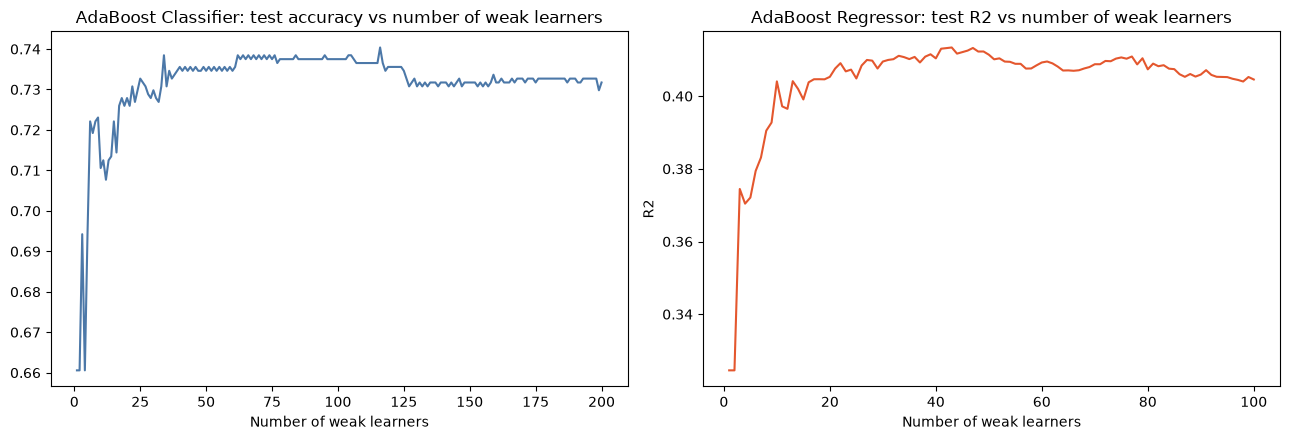

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(range(1, len(acc_stage)+1), acc_stage, color='#4C78A8')
ax[0].set_title('AdaBoost Classifier: test accuracy vs number of weak learners')
ax[1].plot(range(1, len(r2_stage)+1), r2_stage, color='#E4572E')
ax[1].set_title('AdaBoost Regressor: test R2 vs number of weak learners')
for a, y in zip(ax, ['Accuracy', 'R2']): a.set_xlabel('Number of weak learners')
a.set_ylabel(y)
plt.tight_layout()
plt.savefig('../Images/03_adaboost_sequential.png')
plt.show()

**Interpretation:** Each added weak learner corrects the mistakes of the previous ones, so performance rises quickly in the first tens of learners and then flattens. This is boosting reducing bias sequentially; the flat tail shows extra learners give diminishing returns.

### D2. XGBoost

In [13]:
eval_cls('XGBoost Classifier', XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, 
                                            colsample_bytree=0.8, random_state=42, eval_metric='logloss'))

eval_reg('XGBoost Regressor', XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, 
                                            subsample=0.8, colsample_bytree=0.8, random_state=42))

display(pd.DataFrame(cls_rows).set_index('Model').loc[['AdaBoost Classifier', 'XGBoost Classifier']].round(4))
display(pd.DataFrame(reg_rows).set_index('Model').loc[['AdaBoost Regressor', 'XGBoost Regressor']].round(4))

,Accuracy,Precision,Recall,F1,AUC,Train_Acc
Model,,,,,,
AdaBoost Classifier,0.7317,0.6762,0.5462,0.6043,0.7876,0.7377
XGBoost Classifier,0.7317,0.6618,0.5821,0.6194,0.7787,0.8358


,MAE,RMSE,R2,Train_R2
Model,,,,
AdaBoost Regressor,8.4908,10.4112,0.4046,0.4949
XGBoost Regressor,8.2026,10.2063,0.4278,0.6738


**Interpretation:** AdaBoost: accuracy 0.732, AUC 0.788, R2 0.405. XGBoost: accuracy 0.723, AUC 0.772, recall 0.574, and the best boosting regressor (RMSE 10.19, R2 0.429). The two are close on classification (AdaBoost has slightly better AUC, XGBoost slightly better recall); XGBoost wins on regression thanks to regularisation, subsampling and deeper trees. XGBoost fits training data more tightly (train acc 0.835 vs test 0.723), so it needs mild regularisation.

## Part E - Voting & Stacking

In [14]:
base_c = [('lr', LogisticRegression(max_iter=2000)), 
            ('knn', KNeighborsClassifier(n_neighbors=7)),
            ('dt', DecisionTreeClassifier(max_depth=5, random_state=42)), 
            ('svm', SVC(probability=True, random_state=42))
        ]

base_r = [('ridge', Ridge()), 
            ('knn', KNeighborsRegressor(n_neighbors=7)),
            ('dt', DecisionTreeRegressor(max_depth=5, random_state=42)), 
            ('svr', SVR())
        ]

eval_cls('Hard Voting', VotingClassifier(base_c, voting='hard'))
eval_cls('Soft Voting', VotingClassifier(base_c, voting='soft'))
eval_cls('Stacking Classifier', StackingClassifier(base_c, final_estimator=LogisticRegression(), cv=5, n_jobs=-1))

eval_reg('Stacking Regressor', StackingRegressor(base_r, final_estimator=Ridge(), cv=5, n_jobs=-1))

display(pd.DataFrame(cls_rows).set_index('Model').loc[['Hard Voting', 'Soft Voting', 'Stacking Classifier']].round(4))
display(pd.DataFrame(reg_rows).set_index('Model').loc[['Stacking Regressor']].round(4))

c:\Users\Rensee\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Rensee\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision,Recall,F1,AUC,Train_Acc
Model,,,,,,
Hard Voting,0.7346,0.7065,0.5000,0.5856,0.6877,0.7627
Soft Voting,0.7394,0.6951,0.5436,0.6101,0.7816,0.7683
Stacking Classifier,0.7394,0.6820,0.5718,0.6220,0.7931,0.7411


,MAE,RMSE,R2,Train_R2
Model,,,,
Stacking Regressor,8.0344,9.9942,0.4513,0.5127


**Interpretation:** Soft voting (accuracy 0.739, AUC 0.782) beats hard voting (AUC 0.688, recall 0.50) because averaging probabilities keeps each model's confidence instead of discarding it. Stacking is best overall (AUC 0.793, F1 0.622, recall 0.572): its Logistic Regression meta-learner learns how much to trust each base model. The Stacking Regressor also leads regression (RMSE 9.99, MAE 8.03, R2 0.451).

## Part F - Model Evaluation & Comparison

In [15]:
cls_tbl = pd.DataFrame(cls_rows).sort_values('AUC', ascending=False).round(4).reset_index(drop=True)
reg_tbl = pd.DataFrame(reg_rows).sort_values('RMSE').round(4).reset_index(drop=True)

cls_tbl.to_csv('../Outputs/classification_results.csv', index=False)
reg_tbl.to_csv('../Outputs/regression_results.csv', index=False)

display(cls_tbl)
display(reg_tbl)

,Model,Accuracy,Precision,Recall,F1,AUC,Train_Acc
0,Stacking Classifier,0.7394,0.6820,0.5718,0.6220,0.7931,0.7411
1,AdaBoost Classifier,0.7317,0.6762,0.5462,0.6043,0.7876,0.7377
2,Soft Voting,0.7394,0.6951,0.5436,0.6101,0.7816,0.7683
3,XGBoost Classifier,0.7317,0.6618,0.5821,0.6194,0.7787,0.8358
4,Bagging Classifier,0.7058,0.6193,0.5590,0.5876,0.7584,1.0000
5,Bagging Classifier,0.7058,0.6193,0.5590,0.5876,0.7584,1.0000
6,Hard Voting,0.7346,0.7065,0.5000,0.5856,0.6877,0.7627
7,Decision Tree,0.6173,0.4903,0.5205,0.5050,0.5979,1.0000
8,Decision Tree,0.6173,0.4903,0.5205,0.5050,0.5979,1.0000


,Model,MAE,RMSE,R2,Train_R2
0,Stacking Regressor,8.0344,9.9942,0.4513,0.5127
1,XGBoost Regressor,8.2026,10.2063,0.4278,0.6738
2,Bagging Regressor,8.3061,10.2951,0.4178,0.9246
3,Bagging Regressor,8.3061,10.2951,0.4178,0.9246
4,AdaBoost Regressor,8.4908,10.4112,0.4046,0.4949
5,Decision Tree,11.1783,14.1096,-0.0936,1.0000
6,Decision Tree,11.1783,14.1096,-0.0936,1.0000


**Interpretation:** Classification ranking by AUC: Stacking (0.793) > AdaBoost (0.788) > Soft Voting (0.782) > XGBoost (0.772) > Bagging (0.758) > Hard Voting (0.688) > Decision Tree (0.598). Regression ranking by RMSE: Stacking (9.99) > XGBoost (10.19) > Bagging (10.30) > AdaBoost (10.41) > Decision Tree (14.19). Every ensemble beats the single tree; the top models are separated by small margins.

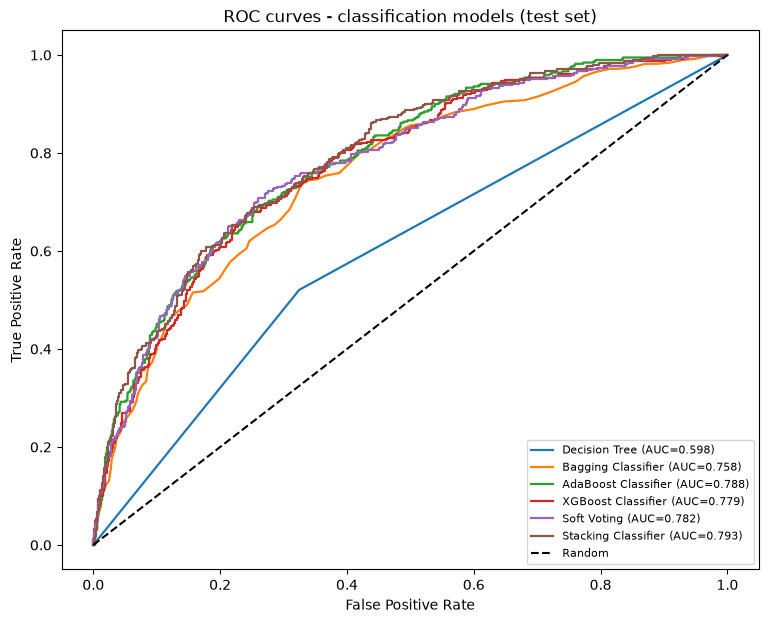

In [16]:
plt.figure(figsize=(9, 7))
for n, m in cls_models.items():
    if n == 'Hard Voting': continue
    p = m.predict_proba(Xte)[:, 1]; fpr, tpr, _ = roc_curve(yc_test, p)
    plt.plot(fpr, tpr, lw=1.6, label=f"{n} (AUC={roc_auc_score(yc_test, p):.3f})")
    
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curves - classification models (test set)')
plt.legend(loc='lower right', fontsize=8)
plt.savefig('../Images/04_roc_curves.png')
plt.show()

**Interpretation:** Stacking, AdaBoost and Soft Voting curves are the highest and nearly overlap; the single Decision Tree is close to the diagonal (weak ranking ability). Ensembles clearly separate completers from non-completers better than a single tree.

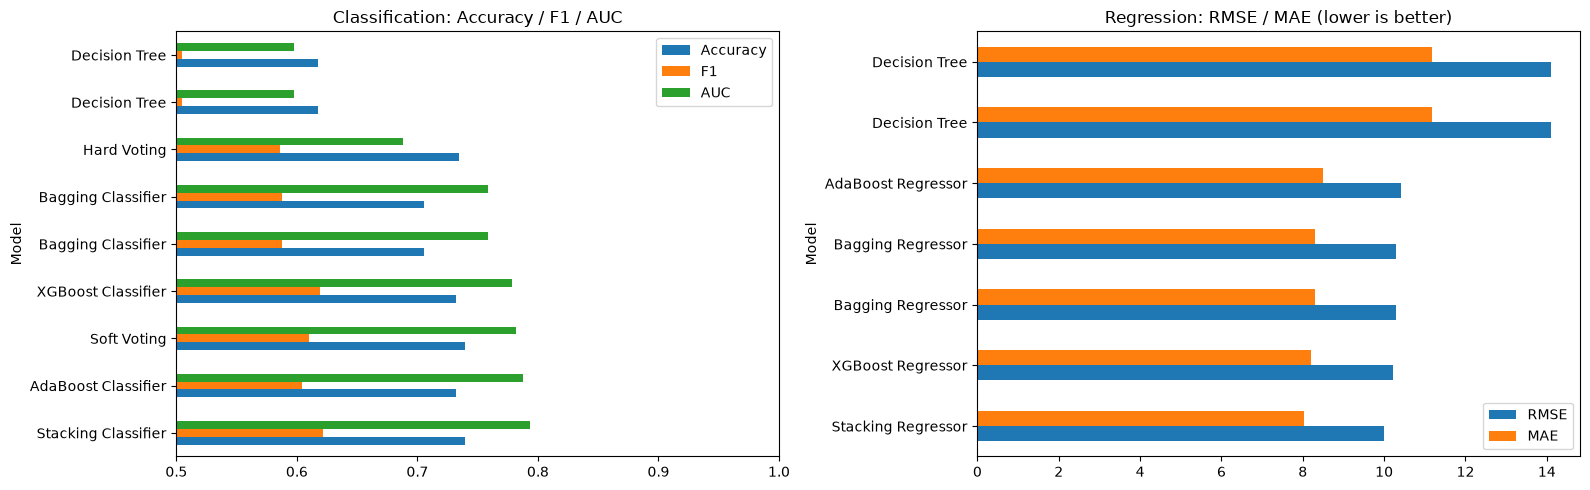

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

cls_tbl.set_index('Model')[['Accuracy', 'F1', 'AUC']].plot.barh(ax=ax[0])
ax[0].set_xlim(0.5, 1); ax[0].set_title('Classification: Accuracy / F1 / AUC')

reg_tbl.set_index('Model')[['RMSE', 'MAE']].plot.barh(ax=ax[1])
ax[1].set_title('Regression: RMSE / MAE (lower is better)')

plt.tight_layout()
plt.savefig('../Images/05_model_comparison.png')
plt.show()

**Interpretation:** The bars confirm that ensembles beat the Decision Tree on every metric, and that Stacking leads both tasks. Differences among Stacking, boosting and soft voting are small (about 0.01 AUC / 0.2-0.4 RMSE).

Best classifier (highest AUC): Stacking Classifier
Best regressor  (lowest RMSE): Stacking Regressor


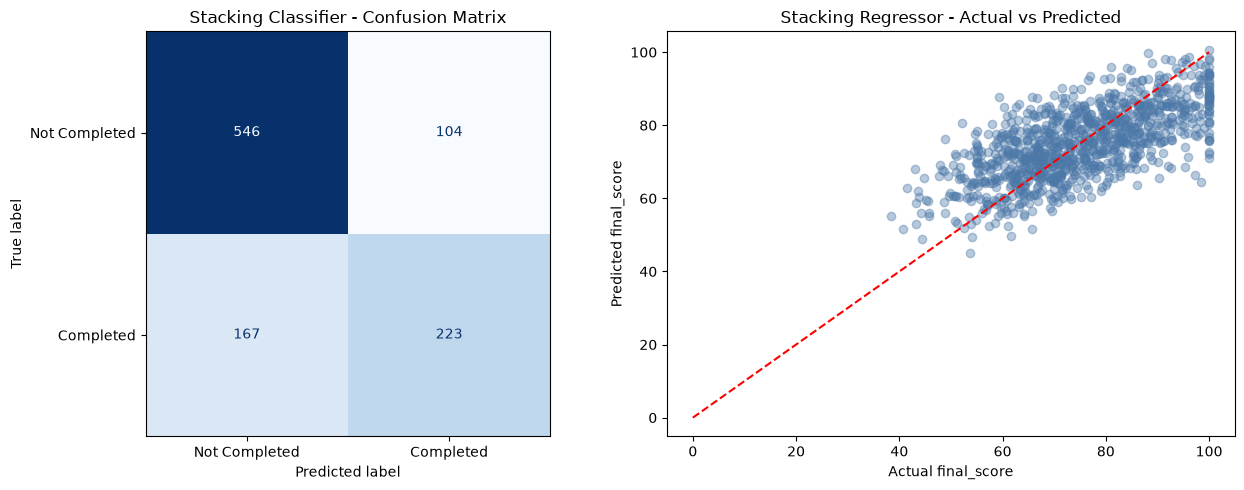

In [18]:
best_cls, best_reg = cls_tbl.loc[0, 'Model'], reg_tbl.loc[0, 'Model']
print('Best classifier (highest AUC):', best_cls)
print('Best regressor  (lowest RMSE):', best_reg)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(yc_test, cls_models[best_cls].predict(Xte)), 
                        display_labels=['Not Completed', 'Completed']).plot(ax=ax[0], 
                        cmap='Blues', colorbar=False)

ax[0].set_title(f'{best_cls} - Confusion Matrix')
ax[0].grid(False)
ax[1].scatter(yr_test, reg_models[best_reg].predict(Xte), alpha=0.4, color='#4C78A8')
ax[1].plot([0, 100], [0, 100], 'r--')
ax[1].set_xlabel('Actual final_score')
ax[1].set_ylabel('Predicted final_score')
ax[1].set_title(f'{best_reg} - Actual vs Predicted')
plt.tight_layout()
plt.savefig('../Images/06_best_models.png')
plt.show()

**Interpretation:** The Stacking Classifier correctly classifies about 74% of students, but it misses a share of completers (recall 0.57), a limit of the available features. The regression plot shows predictions follow the diagonal but are compressed toward the mean (R2 0.45), with larger errors for very high and very low scores.

### Final Pipelines, Pickle files 

In [19]:
cls_pipe = Pipeline([
    ('prep', make_preprocessor()), 
    ('clf', clone(cls_models[best_cls]))
]).fit(X_train, yc_train)

reg_pipe = Pipeline([
    ('prep', make_preprocessor()), 
    ('reg', clone(reg_models[best_reg]))
]).fit(X_train, yr_train)

pc = cls_pipe.predict(X_test) 
pp = cls_pipe.predict_proba(X_test)[:, 1]
pr = reg_pipe.predict(X_test)

cm = {
    'Accuracy': accuracy_score(yc_test, pc),
    'Precision': precision_score(yc_test, pc),
    'Recall': recall_score(yc_test, pc),
    'F1': f1_score(yc_test, pc),
    'AUC': roc_auc_score(yc_test, pp)
}

rm = {
    'MAE': mean_absolute_error(yr_test, pr),
    'RMSE': np.sqrt(mean_squared_error(yr_test, pr)),
    'R2': r2_score(yr_test, pr)
}

pickle.dump(cls_pipe, open('../Models/completion_pipeline.pkl', 'wb'))
pickle.dump(reg_pipe, open('../Models/score_pipeline.pkl', 'wb'))

info = {'classifier': best_cls, 
        'regressor': best_reg,
        'classification_metrics': {k: round(float(v), 4) for k, v in cm.items()},
        'regression_metrics': {k: round(float(v), 4) for k, v in rm.items()},
        'features': FEATURES, 
        'num': NUM, 
        'cat': CAT,
        'cat_options': {c: sorted(df[c].unique().tolist()) for c in CAT},
        'num_ranges': {c: [float(df[c].min()), float(df[c].max()), float(df[c].median())] for c in NUM},
        'all_classification': cls_tbl.to_dict('records'), 'all_regression': reg_tbl.to_dict('records')
    }

json.dump(info, open('../Models/final_metrics.json', 'w'), indent=4)

print(info['classifier'], info['classification_metrics'])
print(info['regressor'], info['regression_metrics'])
print('Saved')

Stacking Classifier {'Accuracy': 0.7394, 'Precision': 0.682, 'Recall': 0.5718, 'F1': 0.622, 'AUC': 0.7931}
Stacking Regressor {'MAE': 8.0344, 'RMSE': 9.9942, 'R2': 0.4513}
Saved


## Part G - Final Report

**1. Bagging vs Boosting.** Bagging mainly reduces variance: it lifted the Decision Tree from AUC 0.598 to 0.758 and cut regression RMSE from 14.19 to 10.30, but its trees still fit training data perfectly (train acc 1.00). Boosting reduces bias sequentially with weak learners and gives better test results with a smaller train-test gap (AdaBoost AUC 0.788, XGBoost RMSE 10.19). Boosting was slightly better than bagging on both tasks.

**2. Tree-based boosting comparison.** AdaBoost (stumps) is simple and competitive for classification (AUC 0.788) but is the weakest ensemble regressor (RMSE 10.41). XGBoost is the best boosting regressor (R2 0.429) and has better recall (0.574) thanks to regularisation, shrinkage and subsampling; it is more tunable but overfits more if left unconstrained.

**3. Voting and Stacking.** Soft voting beats hard voting (AUC 0.782 vs 0.688) because it uses probabilities. Stacking is the best on both tasks (AUC 0.793, F1 0.622; RMSE 9.99, R2 0.451) because the meta-learner weights diverse base models (linear, KNN, tree, SVM). Cost: longer training and more complex deployment.

**4. Final recommendation.** Deploy the **Stacking Classifier** (completion) and **Stacking Regressor** (final score), packaged as full preprocessing pipelines (completion_pipeline.pkl, score_pipeline.pkl). If simplicity or speed matters, XGBoost is a close, cheaper alternative (AUC 0.772, RMSE 10.19). Do not use a single Decision Tree.

**5. Business interpretation.** The platform can flag students with a low completion probability (accuracy 74%, precision 0.68) for early support such as reminders, mentoring and quiz help, and forecast final scores within about 8 points on average (MAE 8.0). Engagement and quiz performance (avg_quiz_score, attendance, sessions) are the strongest drivers, so interventions should focus there. Recall is only 0.57, so the tool should support, not replace, human review; adding richer data (e.g. weekly progress trends) is the best way to improve it.